# Hub tests

In round 1, GOAT needed far fewer queries with hub-free distinguishing than with top degree on Chung–Lu and PAPER. This notebook tests why, and whether the effect is specific to GOAT. It reuses the round-1 pairs.

**Question 1: hubs or uniqueness?** Hub-free distinguishing changes two things at once.
- It skips the 10 highest-degree vertices (the hubs).
- It picks seeds that make vertices easier to tell apart.

A new rule, **hub-free top degree**, only skips the hubs:

| | by degree | by uniqueness |
|---|---|---|
| hubs kept | top degree | distinguishing |
| hubs skipped | **hub-free top degree** (new) | hub-free distinguishing |

**Question 2: wrong hints or too broad?** A hub tells each of its many neighbours (up to about 100) "you are next to me", but about half of those edges are missing or different in B. The new run **top degree, clean hub edges** keeps round 1's top-degree seeds. It makes each seeded hub's edges in B the same as in A, so every hint from a hub is correct. Nothing else changes.

**Question 3: are hubs harmful or just wasted?** (added 27 Oct) The first 6, 8 or 10 hub-free top-degree seeds are run again with the 1, 2 or 5 highest-degree hubs added. The comparison is with the same ordinary seeds alone.

**Question 4: is it specific to GOAT?** (added 27 Oct) Hub-free top degree is run with FAQ and percolation on their round-1 pairs, with round-1 settings: FAQ gets up to 3 restarts and stops at the first success, and percolation gets one run.

**How to read the results** (written before the runs)
- **Question 1:**
  - If hub-free top degree does about as well as hub-free distinguishing, skipping hubs is what matters.
  - If hub-free distinguishing needs clearly fewer queries, uniqueness adds to it.
- **Question 2:**
  - If top degree with clean hub edges catches up with hub-free top degree, the hubs' wrong hints are the problem.
  - If it stays near top degree, hubs hurt even when their hints are right.
  - Clean edges are better than any real seed's, so some jump is expected either way. The test only asks whether broad hints hurt when they are right.
- **Question 3:**
  - If success drops when hubs are added, hubs actively hurt GOAT.
  - If it stays the same, hubs are wasted queries.
  - If it rises, hubs help, just less than ordinary seeds.
- **Question 4:** if hub-free top degree beats top degree only under GOAT, the effect is specific to GOAT.

**Run time.** Questions 1 and 2 took about 6 minutes. Questions 3 and 4 add about 20–30 minutes. Round-1 results are reused for the other rules, so only the new runs are made. FAQ uses its round-1 pairs (10 now). If FAQ's round 1 is extended to 20 pairs (`borderline_check.ipynb`), rerunning this notebook adds the new pairs.

In [1]:
import os
import sys
import tempfile
from pathlib import Path

os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'sgm_matplotlib_cache'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

EXPERIMENT_DIR = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / 'experiment_common').is_dir()) / 'selection_rule_comparison'
if EXPERIMENT_DIR.name != 'selection_rule_comparison':
    EXPERIMENT_DIR = EXPERIMENT_DIR / 'selection_rule_comparison'
if str(EXPERIMENT_DIR.parent) not in sys.path:
    sys.path.insert(0, str(EXPERIMENT_DIR.parent))

from selection_rule_comparison.archive import hub_test as H

RUN_EXPERIMENTS = True   # False: only analyse saved results
MODELS = list(H.MODELS)
COLORS = {'random': '#9E9E9E', 'top_degree': '#222222', 'distinguishing': '#2CA02C',
          'hub_free_distinguishing': '#9467BD', 'hub_free_top_degree': '#FF7F0E',
          'top_degree_clean_hubs': '#222222'}
LINESTYLES = {'top_degree_clean_hubs': '--'}

## Run

Progress prints below, one line per pair. Rerunning skips pairs that are already done. You can also run it in a terminal from the repository root: `python -m selection_rule_comparison.hub_test`.

In [2]:
if RUN_EXPERIMENTS:
    H.run_all(jobs=3)

00:32:28 100 pairs to run, 3 at a time: about 11 minutes.
00:33:03 [1/100] GOAT add-hubs Chung-Lu pair 1: 9 runs in 28 s
00:33:18 [2/100] GOAT add-hubs Chung-Lu pair 2: 9 runs in 42 s
00:33:21 [3/100] GOAT add-hubs Chung-Lu pair 0: 9 runs in 45 s
00:33:44 [4/100] GOAT add-hubs Chung-Lu pair 3: 9 runs in 40 s
00:34:06 [5/100] GOAT add-hubs Chung-Lu pair 5: 9 runs in 45 s
00:34:06 [6/100] GOAT add-hubs Chung-Lu pair 4: 9 runs in 48 s
00:34:13 [7/100] GOAT add-hubs Chung-Lu pair 6: 9 runs in 29 s
00:34:37 [8/100] GOAT add-hubs Chung-Lu pair 9: 9 runs in 25 s
00:34:47 [9/100] GOAT add-hubs Chung-Lu pair 8: 9 runs in 41 s
00:34:56 [10/100] GOAT add-hubs Chung-Lu pair 7: 9 runs in 51 s
00:35:25 [11/100] GOAT add-hubs Chung-Lu pair 10: 9 runs in 48 s
00:35:53 [12/100] GOAT add-hubs Chung-Lu pair 11: 9 runs in 66 s
00:36:02 [13/100] GOAT add-hubs Chung-Lu pair 12: 9 runs in 66 s
00:36:18 [14/100] GOAT add-hubs Chung-Lu pair 13: 9 runs in 53 s
00:36:31 [15/100] GOAT add-hubs Chung-Lu pair 15: 9

/Users/langsong/miniforge3/envs/ds/lib/python3.11/site-packages/graspologic/match/solver.py:383: UserWarning: Sinkhorn-Knopp algorithm for solving linear sum transport problem did not converge. The final error was 0.06166742237701089 and the `transport_tol` was 0.05. You may want to consider increasing `transport_regularizer`, increasing `transport_max_iter`, or this could be the result of `transport_tol` set too small.
  warnings.warn(


00:40:42 [53/100] GOAT add-hubs PAPER pair 0: 9 runs in 53 s
00:40:52 [54/100] GOAT add-hubs PAPER pair 3: 9 runs in 41 s
00:40:59 [55/100] GOAT add-hubs PAPER pair 4: 9 runs in 43 s
00:41:10 [56/100] GOAT add-hubs PAPER pair 7: 9 runs in 12 s


/Users/langsong/miniforge3/envs/ds/lib/python3.11/site-packages/graspologic/match/solver.py:383: UserWarning: Sinkhorn-Knopp algorithm for solving linear sum transport problem did not converge. The final error was 0.0923653925395068 and the `transport_tol` was 0.05. You may want to consider increasing `transport_regularizer`, increasing `transport_max_iter`, or this could be the result of `transport_tol` set too small.
  warnings.warn(


00:41:20 [57/100] GOAT add-hubs PAPER pair 6: 9 runs in 28 s
00:41:39 [58/100] GOAT add-hubs PAPER pair 8: 9 runs in 29 s
00:41:45 [59/100] GOAT add-hubs PAPER pair 5: 9 runs in 63 s


/Users/langsong/miniforge3/envs/ds/lib/python3.11/site-packages/graspologic/match/solver.py:383: UserWarning: Sinkhorn-Knopp algorithm for solving linear sum transport problem did not converge. The final error was 0.12121592464974079 and the `transport_tol` was 0.05. You may want to consider increasing `transport_regularizer`, increasing `transport_max_iter`, or this could be the result of `transport_tol` set too small.
  warnings.warn(


... (3 outputs left out)

/Users/langsong/miniforge3/envs/ds/lib/python3.11/site-packages/graspologic/match/solver.py:383: UserWarning: Sinkhorn-Knopp algorithm for solving linear sum transport problem did not converge. The final error was 0.07841918189948036 and the `transport_tol` was 0.05. You may want to consider increasing `transport_regularizer`, increasing `transport_max_iter`, or this could be the result of `transport_tol` set too small.
  warnings.warn(


00:43:02 [64/100] GOAT add-hubs PAPER pair 14: 9 runs in 30 s


/Users/langsong/miniforge3/envs/ds/lib/python3.11/site-packages/graspologic/match/solver.py:383: UserWarning: Sinkhorn-Knopp algorithm for solving linear sum transport problem did not converge. The final error was 0.09174511324224534 and the `transport_tol` was 0.05. You may want to consider increasing `transport_regularizer`, increasing `transport_max_iter`, or this could be the result of `transport_tol` set too small.
  warnings.warn(


00:43:29 [65/100] GOAT add-hubs PAPER pair 13: 9 runs in 61 s
00:43:33 [66/100] GOAT add-hubs PAPER pair 16: 9 runs in 31 s
00:43:35 [67/100] GOAT add-hubs PAPER pair 15: 9 runs in 43 s
00:43:43 [68/100] GOAT add-hubs PAPER pair 17: 9 runs in 14 s
00:43:51 [69/100] GOAT add-hubs PAPER pair 19: 9 runs in 16 s
00:43:51 [70/100] GOAT add-hubs PAPER pair 18: 9 runs in 18 s
00:44:30 [71/100] SGM (FAQ) PAPER pair 2: 12 runs in 39 s
00:44:54 [72/100] SGM (FAQ) PAPER pair 1: 21 runs in 63 s
00:45:19 [73/100] SGM (FAQ) PAPER pair 3: 14 runs in 48 s
00:45:24 [74/100] SGM (FAQ) PAPER pair 0: 29 runs in 101 s
00:45:39 [75/100] SGM (FAQ) PAPER pair 4: 12 runs in 45 s
00:46:04 [76/100] SGM (FAQ) PAPER pair 5: 14 runs in 45 s
00:46:04 [77/100] SGM (FAQ) PAPER pair 7: 8 runs in 25 s
00:46:21 [78/100] SGM (FAQ) PAPER pair 6: 15 runs in 57 s
00:46:28 [79/100] Percolation PAPER pair 0: 12 runs in 7 s
00:46:35 [80/100] Percolation PAPER pair 1: 12 runs in 7 s
00:46:39 [81/100] Percolation PAPER pair 2: 6 

## 1. Check

Plain top degree is rerun on the first two pairs of every algorithm and model. Every run should match round 1, with the same success and the same accuracy.

In [3]:
display(H.check_against_round1(MODELS))

results = H.load_results(MODELS)
queries = H.queries_needed(results)
print('Pairs per model:', {H.MODEL_LABELS[m]: results.loc[results['model'] == m, 'pair_index'].nunique()
                           for m in MODELS})


def plot_success(rules, title):
    fig, axes = plt.subplots(1, len(MODELS), figsize=(5.5 * len(MODELS), 3.8), sharey=True, squeeze=False)
    for ax, model in zip(axes[0], MODELS):
        data = results[results['model'] == model]
        for rule in rules:
            curve = data[data['rule'] == rule].groupby('budget')['success'].mean()
            ax.plot(curve.index, curve.values, marker='o', color=COLORS[rule],
                    linestyle=LINESTYLES.get(rule, '-'), label=H.LABELS[rule])
        ax.set_title(H.MODEL_LABELS[model])
        ax.set_xlabel('seeds')
        ax.set_ylim(-0.03, 1.03)
    axes[0, 0].set_ylabel('success rate')
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=len(rules), frameon=False)
    fig.suptitle(title)
    plt.tight_layout(rect=(0, 0.08, 1, 1))
    plt.show()

runs checked  same success  same accuracy
algorithm   model                                              
GOAT        Chung-Lu            12            12             12
            PAPER               12            12             12
SGM (FAQ)   Chung-Lu            24            24             24
            PAPER               25            25             25
Percolation Chung-Lu            12            12             12
            PAPER               12            12             12

Pairs per model: {'Chung-Lu': 20, 'PAPER': 20}


## 2. Hubs or uniqueness?

The plot shows the four rules of the 2 × 2, with random for reference.

The first table gives the mean number of queries until the first success. The second shows what each rule's seeds look like at 10 seeds. Skipping hubs also raises uniqueness, so read the two tables together.

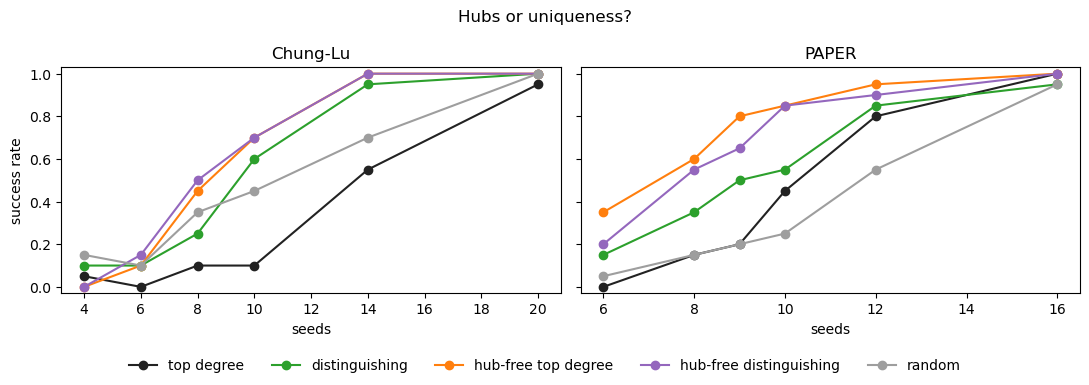

Mean queries needed (lower is better)


Chung-Lu                   PAPER              
             by degree by uniqueness by degree by uniqueness
hubs kept         15.9          10.6      11.2          10.3
hubs skipped      10.1           9.9       8.4           8.8

Seeds at 10 queries (means over pairs)


Chung-Lu                  PAPER           
                        seed degree uniqueness seed degree uniqueness
top degree                    66.18       0.36       34.31       0.71
distinguishing                56.18       0.54       32.95       0.77
hub-free top degree           40.01       0.58       24.89       0.76
hub-free distinguishing       37.80       0.66       24.62       0.81
random                        16.44       0.49       15.48       0.53

In [4]:
plot_success(['top_degree', 'distinguishing', 'hub_free_top_degree', 'hub_free_distinguishing', 'random'],
             'Hubs or uniqueness?')

mean_queries = queries.groupby(['model', 'rule'])['queries'].mean()
grid = pd.DataFrame({
    (H.MODEL_LABELS[m], column): [mean_queries[(m, kept)], mean_queries[(m, skipped)]]
    for m in MODELS
    for column, kept, skipped in [('by degree', 'top_degree', 'hub_free_top_degree'),
                                  ('by uniqueness', 'distinguishing', 'hub_free_distinguishing')]
}, index=['hubs kept', 'hubs skipped'])
print('Mean queries needed (lower is better)')
display(grid.round(1))

at_10 = results[results['budget'] == 10]
profile = {}
for m in MODELS:
    means = at_10[at_10['model'] == m].groupby('rule')[['f_degree', 'f_signature_r3']].mean()
    profile[(H.MODEL_LABELS[m], 'seed degree')] = means['f_degree']
    profile[(H.MODEL_LABELS[m], 'uniqueness')] = means['f_signature_r3']
rules = ['top_degree', 'distinguishing', 'hub_free_top_degree', 'hub_free_distinguishing', 'random']
profile = pd.DataFrame(profile).reindex(rules)
profile.index = [H.LABELS[r] for r in rules]
print('Seeds at 10 queries (means over pairs)')
display(profile.round(2))

## 3. Wrong hints or too broad?

This compares top degree before and after cleaning the hubs' edges in B, against hub-free top degree and random.

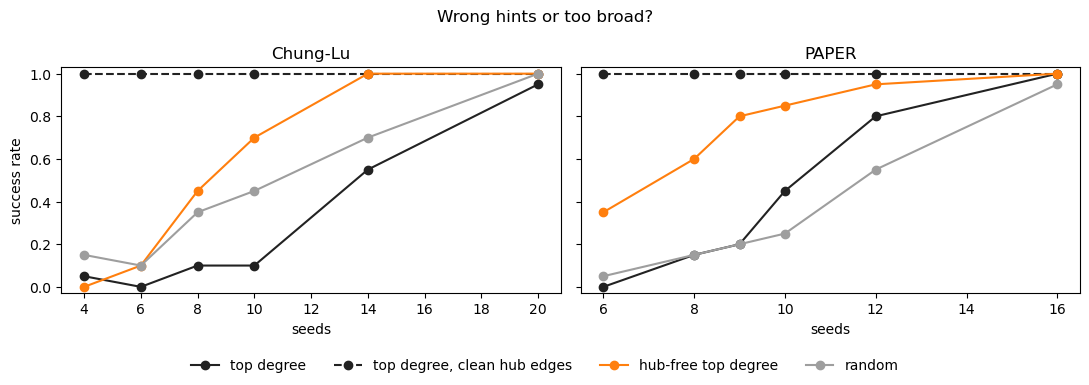

In [5]:
plot_success(['top_degree', 'top_degree_clean_hubs', 'hub_free_top_degree', 'random'], 'Wrong hints or too broad?')

## 4. Queries needed, all rules

**Bars:** the mean number of queries until the first success (lower is better), with 95% bootstrap intervals over pairs. A pair that never succeeds counts as one step past the largest budget: 26 on Chung–Lu and 20 on PAPER.

**Table:** pair-by-pair comparisons of queries needed.
- **Fewer / same / more:** the number of pairs where the first rule needs fewer, the same or more queries than the second.
- **p:** a sign test of fewer against more.
- **Mean change:** first rule minus second, with a 95% bootstrap interval. Negative means the first rule needs fewer queries.

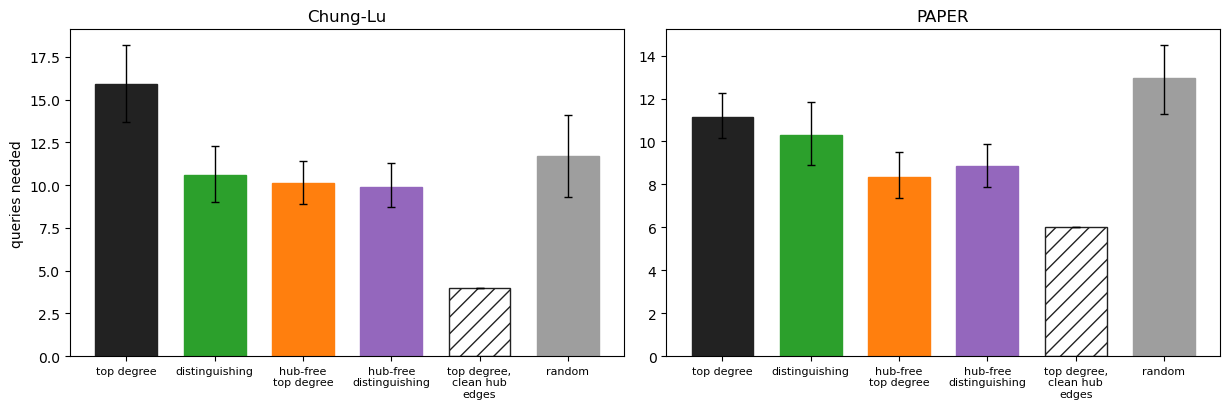

fewer  same  \
model    comparison                                                        
Chung-Lu hub-free top degree vs top degree                      16     2   
         hub-free distinguishing vs hub-free top degree          6     9   
         distinguishing vs top degree                           15     4   
         top degree, clean hub edges vs top degree              19     1   
         top degree, clean hub edges vs hub-free top degree     20     0   
PAPER    hub-free top degree vs top degree                      16     2   
         hub-free distinguishing vs hub-free top degree          3    10   
         distinguishing vs top degree                           11     3   
         top degree, clean hub edges vs top degree              20     0   
         top degree, clean hub edges vs hub-free top degree     13     7   

                                                             more      p  \
model    comparison                                                        
Chung-Lu hub-free top degree vs top degree                      2  0.001   
         hub-free distinguishing vs hub-free top degree         5  1.000   
         distinguishing vs top degree                           1  0.001   
         top degree, clean hub edges vs top degree              0  0.000   
         top degree, clean hub edges vs hub-free top degree     0  0.000   
PAPER    hub-free top degree vs top degree                      2  0.001   
         hub-free distinguishing vs hub-free top degree         7  0.344   
         distinguishing vs top degree                           6  0.332   
         top degree, clean hub edges vs top degree              0  0.000   
         top degree, clean hub edges vs hub-free top degree     0  0.000   

                                                                     mean change  
model    comparison                                                               
Chung-Lu hub-free top degree vs top degree                     -5.8 [-8.2, -3.4]  
         hub-free distinguishing vs hub-free top degree        -0.2 [-1.5, +1.0]  
         distinguishing vs top degree                          -5.3 [-7.3, -3.3]  
         top degree, clean hub edges vs top degree           -11.9 [-14.2, -9.7]  
         top degree, clean hub edges vs hub-free top degree    -6.1 [-7.4, -4.8]  
PAPER    hub-free top degree vs top degree                     -2.8 [-4.1, -1.6]  
         hub-free distinguishing vs hub-free top degree        +0.5 [-0.2, +1.2]  
         distinguishing vs top degree                          -0.8 [-2.2, +0.6]  
         top degree, clean hub edges vs top degree             -5.2 [-6.3, -4.2]  
         top degree, clean hub edges vs hub-free top degree    -2.4 [-3.5, -1.3]

In [6]:
ORDER = ['top_degree', 'distinguishing', 'hub_free_top_degree', 'hub_free_distinguishing',
         'top_degree_clean_hubs', 'random']
BAR_LABELS = {'top_degree': 'top degree', 'distinguishing': 'distinguishing',
              'hub_free_top_degree': 'hub-free\ntop degree', 'hub_free_distinguishing': 'hub-free\ndistinguishing',
              'top_degree_clean_hubs': 'top degree,\nclean hub\nedges', 'random': 'random'}
boot_rng = np.random.default_rng(2026)

fig, axes = plt.subplots(1, len(MODELS), figsize=(6.2 * len(MODELS), 4.2), squeeze=False)
for ax, model in zip(axes[0], MODELS):
    for x, rule in enumerate(ORDER):
        values = queries[(queries['model'] == model) & (queries['rule'] == rule)]['queries'].to_numpy(float)
        low, high = np.percentile(boot_rng.choice(values, size=(2000, len(values))).mean(axis=1), [2.5, 97.5])
        clean = rule == 'top_degree_clean_hubs'
        ax.bar(x, values.mean(), color='white' if clean else COLORS[rule], edgecolor=COLORS[rule],
               hatch='//' if clean else None, width=0.7)
        ax.errorbar(x, values.mean(), yerr=[[values.mean() - low], [high - values.mean()]], color='black',
                    capsize=3, linewidth=1)
    ax.set_xticks(range(len(ORDER)))
    ax.set_xticklabels([BAR_LABELS[r] for r in ORDER], fontsize=8)
    ax.set_title(H.MODEL_LABELS[model])
axes[0, 0].set_ylabel('queries needed')
plt.tight_layout()
plt.show()

CONTRASTS = [('hub_free_top_degree', 'top_degree'),
             ('hub_free_distinguishing', 'hub_free_top_degree'),
             ('distinguishing', 'top_degree'),
             ('top_degree_clean_hubs', 'top_degree'),
             ('top_degree_clean_hubs', 'hub_free_top_degree')]
rows = [{'model': H.MODEL_LABELS[m], 'comparison': f'{H.LABELS[a]} vs {H.LABELS[b]}', **H.compare(queries, m, a, b)}
        for m in MODELS for a, b in CONTRASTS]
display(pd.DataFrame(rows).set_index(['model', 'comparison']).round(3))

## 5. Are hubs harmful or just wasted?

Each line starts from the same ordinary seeds: the first 6, 8 or 10 hub-free top-degree seeds. Moving right adds the 1, 2 or 5 highest-degree hubs to them.

**What to look for**
- **Falling lines:** hubs hurt.
- **Flat lines:** hubs are wasted queries.
- **Rising lines:** hubs help.

The table counts the pairs that went from failure to success (gained) or from success to failure (lost) when the hubs were added. p is a sign test of gained against lost.

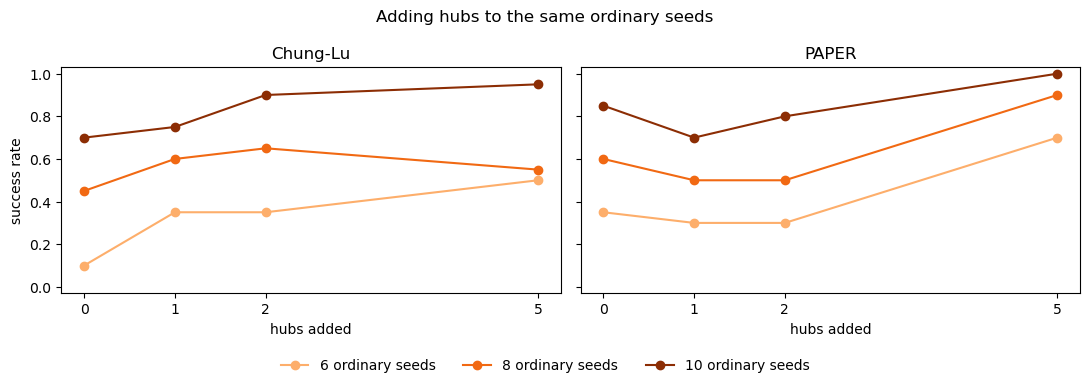

success without  success with  \
model    ordinary seeds hubs added                                  
Chung-Lu 6              1                      0.10          0.35   
                        2                      0.10          0.35   
                        5                      0.10          0.50   
         8              1                      0.45          0.60   
                        2                      0.45          0.65   
                        5                      0.45          0.55   
         10             1                      0.70          0.75   
                        2                      0.70          0.90   
                        5                      0.70          0.95   
PAPER    6              1                      0.35          0.30   
                        2                      0.35          0.30   
                        5                      0.35          0.70   
         8              1                      0.60          0.50   
                        2                      0.60          0.50   
                        5                      0.60          0.90   
         10             1                      0.85          0.70   
                        2                      0.85          0.80   
                        5                      0.85          1.00   

                                    pairs gained  pairs lost      p  
model    ordinary seeds hubs added                                   
Chung-Lu 6              1                      5           0  0.062  
                        2                      6           1  0.125  
                        5                      8           0  0.008  
         8              1                      4           1  0.375  
                        2                      4           0  0.125  
                        5                      3           1  0.625  
         10             1                      3           2  1.000  
                        2                      5           1  0.219  
                        5                      6           1  0.125  
PAPER    6              1                      2           3  1.000  
                        2                      2           3  1.000  
                        5                      7           0  0.016  
         8              1                      1           3  0.625  
                        2                      2           4  0.688  
                        5                      8           2  0.109  
         10             1                      0           3  0.250  
                        2                      1           2  1.000  
                        5                      3           0  0.250

In [7]:
added = H.load_add_hubs(MODELS)
SHADES = {6: '#FDAE6B', 8: '#F16913', 10: '#8C2D04'}

fig, axes = plt.subplots(1, len(MODELS), figsize=(5.5 * len(MODELS), 3.8), sharey=True, squeeze=False)
for ax, model in zip(axes[0], MODELS):
    data = added[added['model'] == model]
    for ordinary, part in data.groupby('ordinary'):
        curve = part.groupby('hubs_added')['success'].mean()
        ax.plot(curve.index, curve.values, marker='o', color=SHADES[ordinary], label=f'{ordinary} ordinary seeds')
    ax.set_title(H.MODEL_LABELS[model])
    ax.set_xlabel('hubs added')
    ax.set_xticks(sorted(added['hubs_added'].unique()))
    ax.set_ylim(-0.03, 1.03)
axes[0, 0].set_ylabel('success rate')
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=len(labels), frameon=False)
fig.suptitle('Adding hubs to the same ordinary seeds')
plt.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

display(H.add_hubs_table(added).round(3))

## 6. Is it specific to GOAT?

Each row is an algorithm, run on its own round-1 pairs and budgets: top degree, hub-free top degree and random.

The table gives the mean queries needed and compares hub-free top degree with top degree pair by pair, using the same columns as section 4.

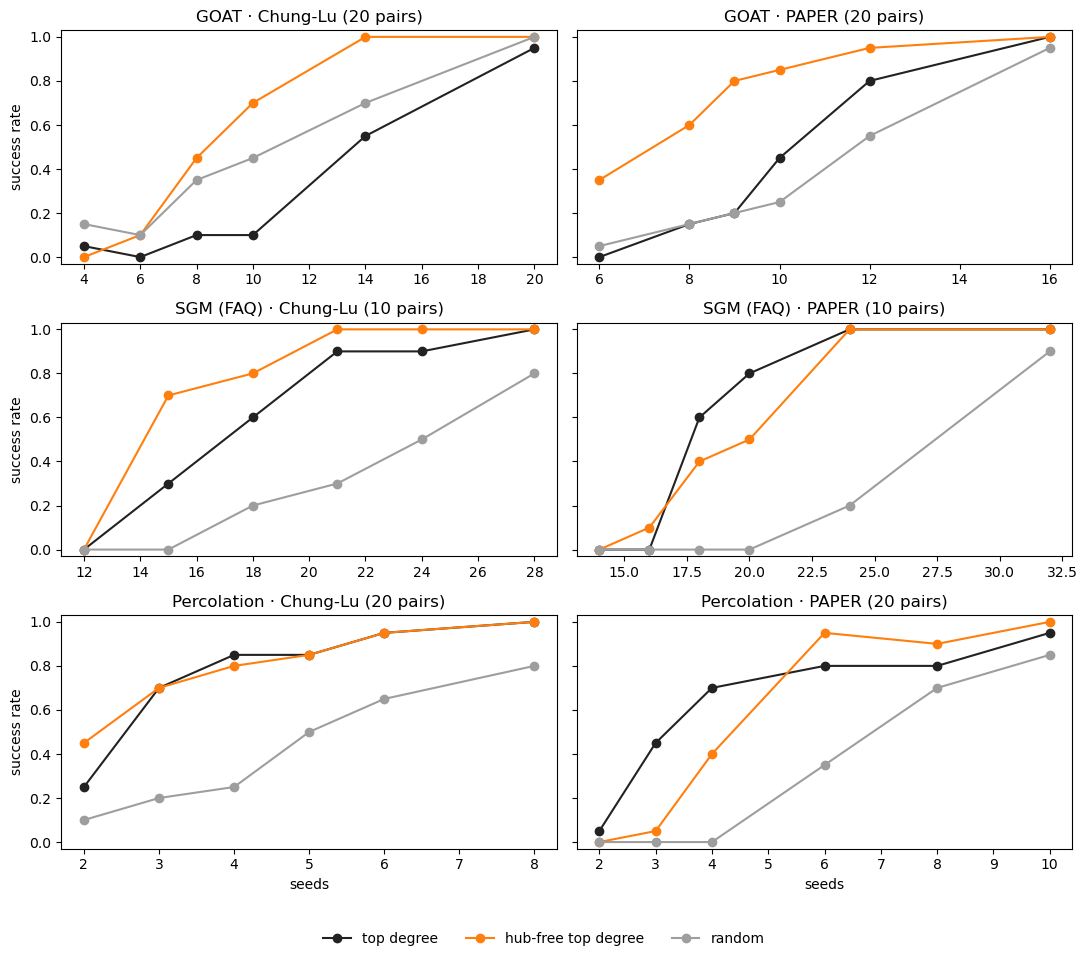

Hub-free top degree vs top degree


mean queries: top degree  \
algorithm   model                                
GOAT        Chung-Lu                     15.90   
            PAPER                        11.15   
SGM (FAQ)   Chung-Lu                     18.60   
            PAPER                        19.60   
Percolation Chung-Lu                      3.25   
            PAPER                         4.35   

                      mean queries: hub-free top degree  mean queries: random  \
algorithm   model                                                               
GOAT        Chung-Lu                              10.10                 11.70   
            PAPER                                  8.35                 12.95   
SGM (FAQ)   Chung-Lu                              16.50                 25.30   
            PAPER                                 20.60                 31.20   
Percolation Chung-Lu                               3.10                  5.70   
            PAPER                                  5.25                  8.20   

                      fewer  same  more      p        mean change  
algorithm   model                                                  
GOAT        Chung-Lu     16     2     2  0.001  -5.8 [-8.2, -3.4]  
            PAPER        16     2     2  0.001  -2.8 [-4.1, -1.6]  
SGM (FAQ)   Chung-Lu      5     5     0  0.062  -2.1 [-3.9, -0.6]  
            PAPER         2     4     4  0.688  +1.0 [-0.4, +2.6]  
Percolation Chung-Lu     10     3     7  0.629  -0.1 [-0.8, +0.5]  
            PAPER         3     5    12  0.035  +0.9 [-0.3, +1.9]

In [8]:
by_algorithm = H.load_algorithm_results(MODELS)
by_algorithm_queries = H.queries_needed(by_algorithm)
ALGORITHMS = [a for a in ['goat', 'faq', 'percolation'] if a in set(by_algorithm['algorithm'])]
RULES = ['top_degree', 'hub_free_top_degree', 'random']

fig, axes = plt.subplots(len(ALGORITHMS), len(MODELS), figsize=(5.5 * len(MODELS), 3.2 * len(ALGORITHMS)),
                         sharey=True, squeeze=False)
for row, algorithm in enumerate(ALGORITHMS):
    for column, model in enumerate(MODELS):
        ax = axes[row, column]
        data = by_algorithm[(by_algorithm['algorithm'] == algorithm) & (by_algorithm['model'] == model)]
        for rule in RULES:
            curve = data[data['rule'] == rule].groupby('budget')['success'].mean()
            ax.plot(curve.index, curve.values, marker='o', color=COLORS[rule], label=H.LABELS[rule])
        pairs = data['pair_index'].nunique()
        ax.set_title(f'{H.ALGORITHM_LABELS[algorithm]} · {H.MODEL_LABELS[model]} ({pairs} pairs)')
        ax.set_ylim(-0.03, 1.03)
    axes[row, 0].set_ylabel('success rate')
for ax in axes[-1]:
    ax.set_xlabel('seeds')
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=len(RULES), frameon=False)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

means = by_algorithm_queries.groupby(['algorithm', 'model', 'rule'])['queries'].mean().unstack('rule')
rows = []
for algorithm in ALGORITHMS:
    for model in MODELS:
        rows.append({'algorithm': H.ALGORITHM_LABELS[algorithm], 'model': H.MODEL_LABELS[model],
                     **{f'mean queries: {H.LABELS[r]}': means.loc[(algorithm, model), r] for r in RULES},
                     **H.compare(by_algorithm_queries, model, 'hub_free_top_degree', 'top_degree',
                                 algorithm=algorithm)})
print('Hub-free top degree vs top degree')
display(pd.DataFrame(rows).set_index(['algorithm', 'model']).round(3))